# 1.2 Clasificación y propiedades

## Linealidad

Un sistema es **lineal** si satisface superposición: $$T(a x_1+b x_2)=aT(x_1)+bT(x_2).$$ 

**Ejemplo:** Comparemos $$T(x)=2x$$ con $$N(x)=x^2.$$ Esta comprobación en una muestra ilustra, pero no sustituye, una demostración general.

**Objetivo:** distinguir una propiedad del sistema de la forma de una señal particular.

Error máximo para T: 0.0
Error máximo para N: 10.324364458472491


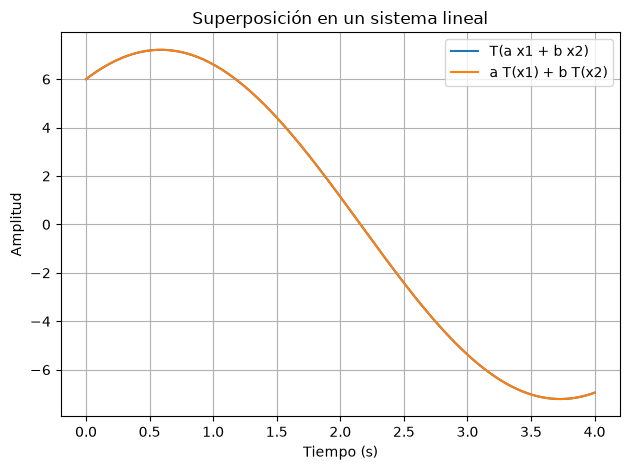

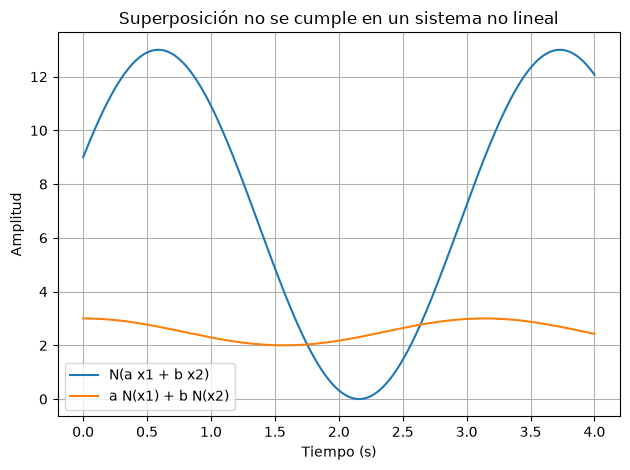

In [21]:
%matplotlib inline
import numpy as np
from sistemas_dinamicos import graficar

t = np.linspace(0, 4, 401)
x1, x2 = np.sin(t), np.cos(t)
a, b = 2, 3
lineal = lambda x: 2 * x
no_lineal = lambda x: x**2
graficar(t, {
    "T(a x1 + b x2)": lineal(a*x1 + b*x2),
    "a T(x1) + b T(x2)": a*lineal(x1) + b*lineal(x2),
}, titulo="Superposición en un sistema lineal");
graficar(t, {
    "N(a x1 + b x2)": no_lineal(a*x1 + b*x2),
    "a N(x1) + b N(x2)": a*no_lineal(x1) + b*no_lineal(x2),
}, titulo="Superposición no se cumple en un sistema no lineal");
print("Error máximo para T:", np.max(np.abs(lineal(a*x1+b*x2) - (a*lineal(x1)+b*lineal(x2)))))
print("Error máximo para N:", np.max(np.abs(no_lineal(a*x1+b*x2) - (a*no_lineal(x1)+b*no_lineal(x2)))))


Las curvas de $T$ coinciden; para $N$ aparece un error porque el cuadrado introduce términos cruzados.

**Practica:** prueba $T(x)=2x+1$. ¿Cumple homogeneidad? Justifica también si depende de valores futuros de la entrada.

## Invariante en el tiempo

Es **invariante en el tiempo** si retrasar la entrada retrasa la salida sin cambiar su forma. 

$$
y(t) = T(x(t)) \to y(t-\tau) = T(x(t-\tau))
$$



Error máximo, sistema invariante: 0.49999984146591725
Error máximo, sistema variante: 0.49999984146591725


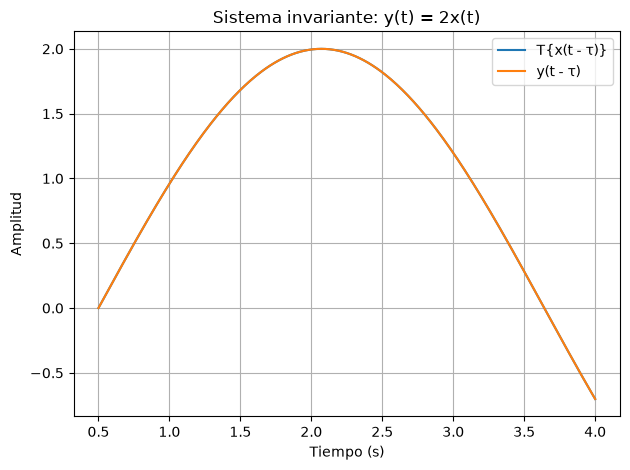

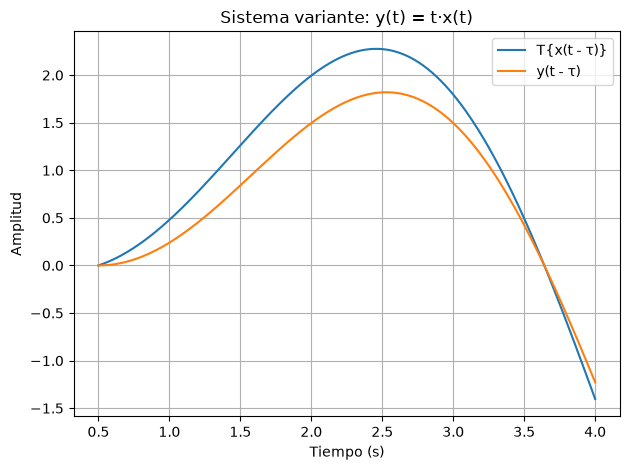

In [22]:
tau = 0.5
valido = t >= tau
t_comparacion = t[valido]

# Entrada retrasada: x(t - tau)
x_retrasada = np.interp(t - tau, t, x1, left=0)

# Caso 1: y(t) = 2x(t), invariante en el tiempo
y_invariante = 2 * x1
salida_entrada_retrasada = 2 * x_retrasada
salida_original_retrasada = np.interp(t - tau, t, y_invariante, left=0)

graficar(t_comparacion, {
    "T{x(t - τ)}": salida_entrada_retrasada[valido],
    "y(t - τ)": salida_original_retrasada[valido],
}, titulo="Sistema invariante: y(t) = 2x(t)")

# Caso 2: y(t) = t·x(t), variante en el tiempo
y_variante = t * x1
salida_entrada_retrasada = t * x_retrasada
salida_original_retrasada = np.interp(t - tau, t, y_variante, left=0)

graficar(t_comparacion, {
    "T{x(t - τ)}": salida_entrada_retrasada[valido],
    "y(t - τ)": salida_original_retrasada[valido],
}, titulo="Sistema variante: y(t) = t·x(t)")

print("Error máximo, sistema invariante:",
      np.max(np.abs(salida_entrada_retrasada[valido] -
                    salida_original_retrasada[valido])))

print("Error máximo, sistema variante:",
      np.max(np.abs(salida_entrada_retrasada[valido] -
                    salida_original_retrasada[valido])))